<a href="https://colab.research.google.com/github/OmMore04/Food-Delivery-Analysis-Using-Python/blob/main/Food_Delivery.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [8]:
df=pd.read_excel(r'/content/cleaned_data (2).xlsx')

In [9]:
df.head(10)

,Order_ID,Order_Date,City,Restaurant_Name,Cuisine,Order_Amount_INR,Delivery_Fee_INR,Payment_Method,Delivery_Time_Min,Customer_Rating,Total_Amount_INR
0,ORD-IN-1001,02/01/2026,Mumbai,Saravana bhavan,South indian,464,49,Cash on delivery,55,4,513
1,ORD-IN-1002,03-Jan-2026,Bengaluru,Dominos pizza,Chinese,637,39,Credit card,37,5,676
2,ORD-IN-1003,2026-01-04,Hyderabad,Saravana bhavan,Chinese,753,39,Upi,39,5,792
3,ORD-IN-1004,05/01/2026,Bengaluru,Bawarchi biryani,North indian,279,49,Credit card,37,5,328
4,ORD-IN-1005,06-Jan-2026,Pune,Mainland china,Fast food,748,39,Upi,39,4,748
5,ORD-IN-1006,2026-01-07,Pune,Dominos pizza,North indian,475,49,Upi,59,4,524
6,ORD-IN-1007,08/01/2026,Pune,Haldirams,North indian,247,49,Google pay,53,5,296
7,ORD-IN-1008,09-Jan-2026,Delhi ncr,Saravana bhavan,North indian,840,59,Upi,25,1,899
8,ORD_IN_1009,2026-01-10,Pune,Haldirams,Biryani,487,49,Upi,35,2,536
9,ORD-IN-1010,11/01/2026,Delhi ncr,Dominos pizza,South indian,536,39,Credit card,42 mins,1,536


In [10]:
pd.isnull(df).sum()

,0
Order_ID,0
Order_Date,0
City,0
Restaurant_Name,0
Cuisine,0
Order_Amount_INR,0
Delivery_Fee_INR,0
Payment_Method,0
Delivery_Time_Min,0
Customer_Rating,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Order_ID           249 non-null    object 
 1   Order_Date         237 non-null    object 
 2   City               249 non-null    object 
 3   Restaurant_Name    249 non-null    object 
 4   Cuisine            249 non-null    object 
 5   Order_Amount_INR   249 non-null    int64  
 6   Delivery_Fee_INR   249 non-null    object 
 7   Payment_Method     249 non-null    object 
 8   Delivery_Time_Min  249 non-null    object 
 9   Customer_Rating    249 non-null    int64  
 10  Total_Amount_INR   240 non-null    float64
dtypes: float64(1), int64(2), object(8)
memory usage: 21.5+ KB


In [11]:
df = df.drop_duplicates()

In [12]:
df.head(20)

,Order_ID,Order_Date,City,Restaurant_Name,Cuisine,Order_Amount_INR,Delivery_Fee_INR,Payment_Method,Delivery_Time_Min,Customer_Rating,Total_Amount_INR
0,ORD-IN-1001,02/01/2026,Mumbai,Saravana bhavan,South indian,464,49,Cash on delivery,55,4,513
1,ORD-IN-1002,03-Jan-2026,Bengaluru,Dominos pizza,Chinese,637,39,Credit card,37,5,676
2,ORD-IN-1003,2026-01-04,Hyderabad,Saravana bhavan,Chinese,753,39,Upi,39,5,792
3,ORD-IN-1004,05/01/2026,Bengaluru,Bawarchi biryani,North indian,279,49,Credit card,37,5,328
4,ORD-IN-1005,06-Jan-2026,Pune,Mainland china,Fast food,748,39,Upi,39,4,748
5,ORD-IN-1006,2026-01-07,Pune,Dominos pizza,North indian,475,49,Upi,59,4,524
6,ORD-IN-1007,08/01/2026,Pune,Haldirams,North indian,247,49,Google pay,53,5,296
7,ORD-IN-1008,09-Jan-2026,Delhi ncr,Saravana bhavan,North indian,840,59,Upi,25,1,899
8,ORD_IN_1009,2026-01-10,Pune,Haldirams,Biryani,487,49,Upi,35,2,536
9,ORD-IN-1010,11/01/2026,Delhi ncr,Dominos pizza,South indian,536,39,Credit card,42 mins,1,536


In [ ]:
df['Delivery_Fee_INR'] = (
    df['Delivery_Fee_INR']
    .astype(str)
    .str.replace(r"[^\d.]", "", regex=True)
)

df['Delivery_Fee_INR'] = pd.to_numeric(
    df['Delivery_Fee_INR'], errors="coerce"
)

df['Delivery_Fee_INR'] = df['Delivery_Fee_INR'].fillna(
    df['Delivery_Fee_INR'].median()
).astype(int)

In [ ]:
df['Total_Amount_INR'] = df['Total_Amount_INR'].fillna('0')

In [13]:
df['Order_ID'] = df['Order_ID'].str.strip()

In [ ]:
df['Order_ID'] = df['Order_ID'].str.upper()

In [ ]:
df['Total_Amount_INR'] = (
    df['Total_Amount_INR']
    .astype(str)
    .str.replace("₹", "", regex=False)
    .str.strip()
)

df['Total_Amount_INR'] = pd.to_numeric(
    df['Total_Amount_INR'], errors="coerce"
).astype("Int64")

In [ ]:
df['Customer_Rating'] = df['Customer_Rating'].mask(df['Customer_Rating'] < 0, 0)

In [14]:
df.head(50)

,Order_ID,Order_Date,City,Restaurant_Name,Cuisine,Order_Amount_INR,Delivery_Fee_INR,Payment_Method,Delivery_Time_Min,Customer_Rating,Total_Amount_INR
0,ORD-IN-1001,02/01/2026,Mumbai,Saravana bhavan,South indian,464,49,Cash on delivery,55,4,513
1,ORD-IN-1002,03-Jan-2026,Bengaluru,Dominos pizza,Chinese,637,39,Credit card,37,5,676
2,ORD-IN-1003,2026-01-04,Hyderabad,Saravana bhavan,Chinese,753,39,Upi,39,5,792
3,ORD-IN-1004,05/01/2026,Bengaluru,Bawarchi biryani,North indian,279,49,Credit card,37,5,328
4,ORD-IN-1005,06-Jan-2026,Pune,Mainland china,Fast food,748,39,Upi,39,4,748
5,ORD-IN-1006,2026-01-07,Pune,Dominos pizza,North indian,475,49,Upi,59,4,524
6,ORD-IN-1007,08/01/2026,Pune,Haldirams,North indian,247,49,Google pay,53,5,296
7,ORD-IN-1008,09-Jan-2026,Delhi ncr,Saravana bhavan,North indian,840,59,Upi,25,1,899
8,ORD_IN_1009,2026-01-10,Pune,Haldirams,Biryani,487,49,Upi,35,2,536
9,ORD-IN-1010,11/01/2026,Delhi ncr,Dominos pizza,South indian,536,39,Credit card,42 mins,1,536


**Statistical Techniques**

In [ ]:
df.describe()

,Order_Amount_INR,Delivery_Fee_INR,Customer_Rating,Total_Amount_INR
count,249.000000,249.000000,249.000000,249.000000
mean,464.301205,40.313253,2.919679,460.734940
std,205.667564,14.691391,2.067796,248.431065
min,0.000000,0.000000,0.000000,0.000000
25%,333.000000,39.000000,1.000000,324.000000
50%,437.000000,39.000000,3.000000,461.000000
75%,587.000000,49.000000,4.000000,613.000000
max,1166.000000,59.000000,10.000000,1215.000000


Visualization Data & Pattern

In [ ]:
df.columns

Index(['Order_ID', 'Order_Date', 'City', 'Restaurant_Name', 'Cuisine',
       'Order_Amount_INR', 'Delivery_Fee_INR', 'Payment_Method',
       'Delivery_Time_Min', 'Customer_Rating', 'Total_Amount_INR'],
      dtype='object')

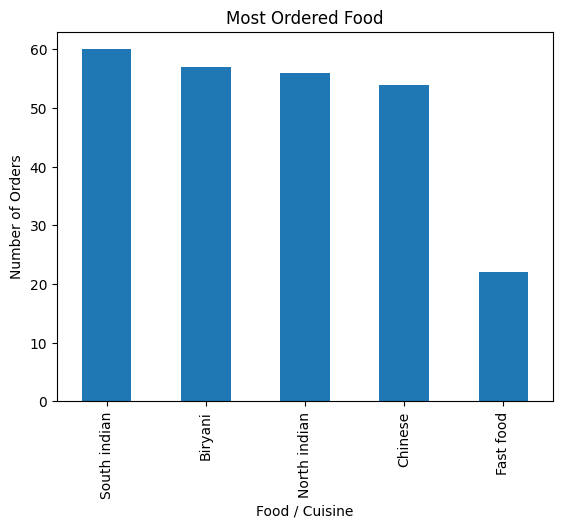

In [15]:
df["Cuisine"].value_counts().plot(kind="bar")

plt.title("Most Ordered Food")
plt.xlabel("Food / Cuisine")
plt.ylabel("Number of Orders")
plt.show()


* The tallest bar = the most ordered cuisine.

* The shortest bar = the least ordered cuisine.

* It helps us understand customer food preferences.

* If one cuisine has a much taller bar than the others, that cuisine is particularly popular in this dataset

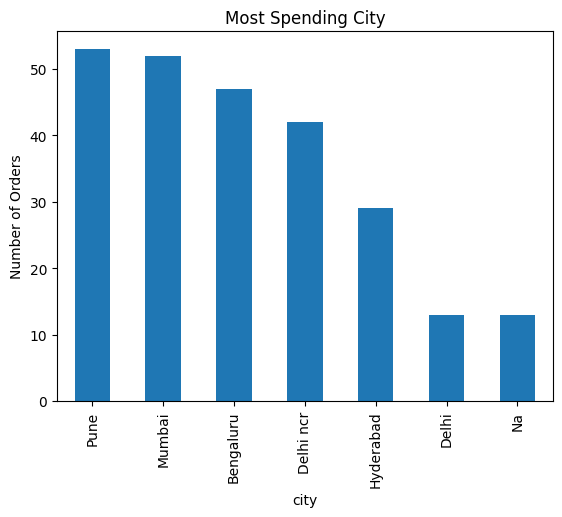

In [16]:
df[ 'City'].value_counts().plot(kind="bar")

plt.title("Most Spending City")
plt.xlabel("city")
plt.ylabel("Number of Orders")
plt.show()

* The bar chart shows the number of food orders from each city.
*  The city with the tallest bar has the highest number of orders, meaning customers from that city placed the most orders in the dataset.

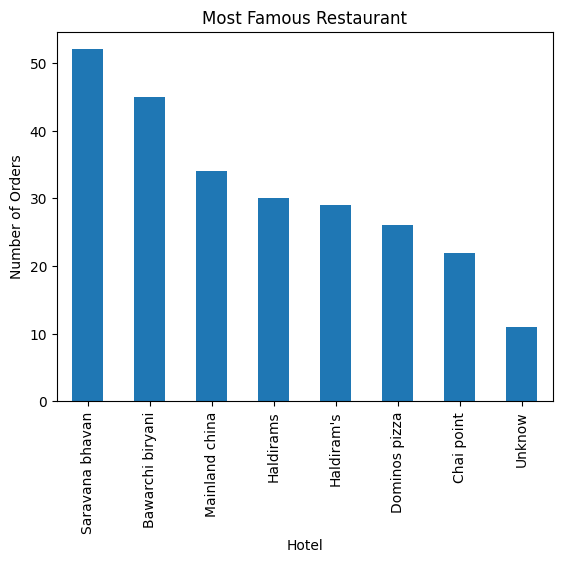

In [17]:
df['Restaurant_Name'].value_counts().plot(kind="bar")

plt.title("Most Famous Restaurant")
plt.xlabel("Hotel")
plt.ylabel("Number of Orders")
plt.show()

* Tallest bar → restaurant with the most orders.

* Shortest bar → restaurant with the fewest orders.

* It helps identify which restaurant is most popular in your dataset.

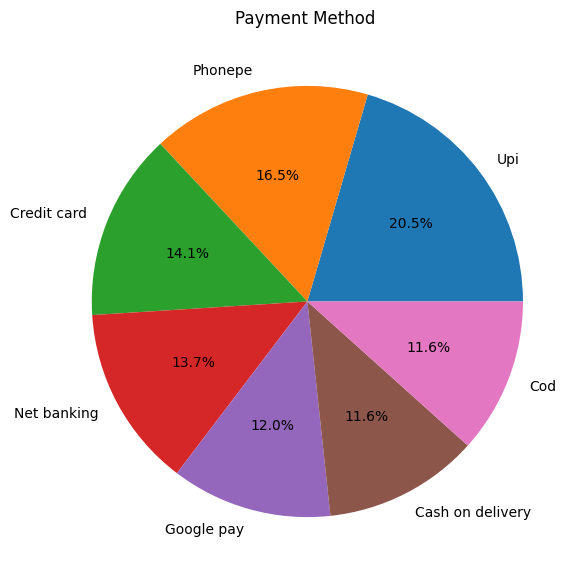

In [18]:
df['Payment_Method'].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7)
)

plt.title("Payment Method ")
plt.ylabel("")   # Remove unnecessary Y-axis label
plt.show()

* The pie chart shows the percentage of customers using each payment method. The largest section represents the most commonly used payment method.

In [19]:
print(df["Delivery_Time_Min"].describe())

count     249
unique     62
top         0
freq       14
Name: Delivery_Time_Min, dtype: object


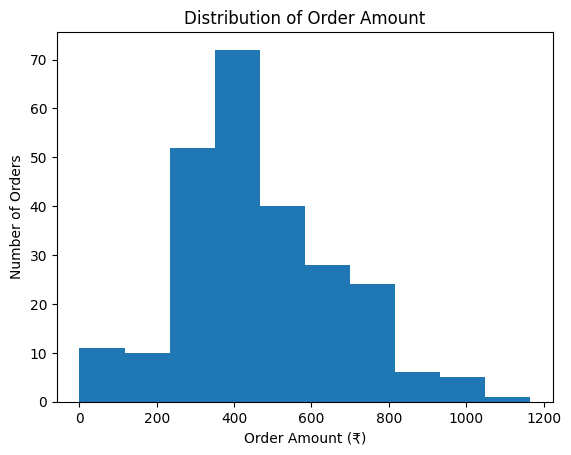

In [22]:


plt.hist(df["Order_Amount_INR"], bins=10)

plt.title("Distribution of Order Amount")
plt.xlabel("Order Amount (₹)")
plt.ylabel("Number of Orders")

plt.show()

* The histogram shows the distribution of order amounts. The bars indicate how many orders fall within different price ranges. Higher bars show the price range where customers place more orders, while lower bars show less common order amounts.

* Most common order range → where the tallest bar appears.

* Low-value orders → bars on the left.

* High-value orders → bars on the right.

* Spread of spending → shows whether order amounts are concentrated or widely distributed.

* Unusual values → very high or very low values may indicate possible outliers.

In [26]:
df.to_excel("cleaned_data.xlsx", index=False)